# Gaussian Processes — Problema 1
## Identificação de uma função escalar com poucos dados

**Referência:** Seção 4.2.5, Exemplo 4.3, de *Control-Oriented System Identification: Classical, Learning, and Physics-Informed Approaches* ([arXiv:2512.06315](https://arxiv.org/html/2512.06315)).

**Propósito deste notebook:** avançar incrementalmente da geração dos dados para a regressão por processos gaussianos (GPR). Inicialmente, construiremos somente o conjunto experimental e o examinaremos. **A identificação do GP ainda não foi implementada.**

**Fonte do código de referência dos autores:** [Structured_GP/structured_GP.ipynb](https://github.com/ExistentialRobotics/physics_based_sysid/blob/main/Structured_GP/structured_GP.ipynb).

---

### 1. Enunciado do problema

Considere um sistema escalar estático em que a saída $y$ depende de uma entrada $x$ por uma função desconhecida $f:\mathbb{R}\rightarrow\mathbb{R}$.

Nosso objetivo é **estimar a função desconhecida a partir de observações ruidosas**, utilizando inicialmente a regressão por processos gaussianos (GPR) convencional e, depois, um GP com estrutura incorporada à média.

Para produzir um experimento reprodutível, a planta simulada é definida por

$$
f_{\mathrm{real}}(x)=\begin{cases}
ax, & x\leq x_{\mathrm{th}},\\
bx, & x>x_{\mathrm{th}},
\end{cases}
\qquad a=1,\quad b=-1,\quad x_{\mathrm{th}}=1.
$$

As observações são dadas por

$$
y_i=f_{\mathrm{real}}(x_i)+\varepsilon_i,
\qquad \varepsilon_i\overset{\mathrm{iid}}{\sim}\mathcal N(0,\sigma_n^2),
\qquad \sigma_n=0.1.
$$

Serão coletadas $N=15$ observações com entradas amostradas uniformemente em $[0,2]$:

$$
x_i\overset{\mathrm{iid}}{\sim}\mathcal U(0,2), \qquad
\mathcal D=\{(x_i,y_i)\}_{i=1}^{15}.
$$

**Separação fundamental:** a função $f_{\mathrm{real}}$ é conhecida **somente pelo simulador**, para gerar os dados e avaliar posteriormente as predições. O identificador receberá apenas $\mathcal D$; ele não receberá a fórmula da planta nem os valores de $a$, $b$ e $x_{\mathrm{th}}$.

> Nota: o Exemplo 4.3 do artigo define a função e os 15 pares observados. O intervalo $[0,2]$, o ruído com desvio-padrão $0.1$ e a semente 1 aparecem no notebook dos autores. O problema é de regressão estática; a identificação de dinâmica temporal virá depois, com o sistema Duffing.

### 2. O que queremos identificar?

Dado um ponto de teste $x_*$, procuraremos estimar a distribuição condicional

$$
p(f(x_*)\mid\mathcal D),
$$

caracterizada, no GP clássico com hiperparâmetros fixados, pela **média posterior** e pela **variância posterior**.

O primeiro modelo será **não estruturado**, ou seja, sem conhecimento da função linear por partes. Em seguida, estudaremos um GP **estruturado**, em que a forma linear por partes aparece na função de média, mas seus parâmetros serão desconhecidos.

**Hipóteses neste primeiro problema:** entrada e saída escalares; função subjacente fixa; ruído gaussiano aditivo, independente e de mesma variância; 15 medições disponíveis.

### 3. Etapas da resolução

1. **Agora — gerar e visualizar os dados.** Conferir o domínio, o ruído, a quantidade de amostras e a distribuição espacial das observações.
2. **Depois — definir o prior do GP convencional.** Discutir o significado da função de média, do kernel e dos hiperparâmetros **antes de programá-los**.
3. **Em seguida — obter a distribuição posterior.** Entender a matriz de covariância e o condicionamento gaussiano; calcular média e incerteza preditiva.
4. **Só então — comparar com o GP estruturado.** Incorporar uma média por partes e verificar como o conhecimento prévio altera o resultado.
5. **Por fim — avaliar.** Comparar curvas, erros e incertezas, com atenção especial à região da descontinuidade.

O código abaixo realiza **apenas o item 1**.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros usados somente para gerar os dados da planta simulada.
N = 15
SIGMA_RUIDO = 0.1
LIMIAR_REAL = 1.0
A_REAL = 1.0
B_REAL = -1.0


def f_real(x):
    """Planta de referência; NÃO deve ser fornecida ao identificador."""
    x = np.asarray(x)
    return np.where(x <= LIMIAR_REAL, A_REAL * x, B_REAL * x)


# RandomState(1) conserva a sequência pseudoaleatória usada no notebook original.
rng = np.random.RandomState(1)
X_train = rng.uniform(0.0, 2.0, size=N)
epsilon = rng.normal(0.0, SIGMA_RUIDO, size=N)
y_train = f_real(X_train) + epsilon

assert X_train.shape == y_train.shape == (15,)

print(f"Observações: {len(X_train)}")
print(f"Intervalo efetivamente amostrado: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"Ruído de geração: desvio-padrão {SIGMA_RUIDO:.2f}")

Observações: 15
Intervalo efetivamente amostrado: [0.000, 1.756]
Ruído de geração: desvio-padrão 0.10


### 4. Inspeção das observações

O gráfico apresenta **somente aquilo que o identificador poderá observar**: os pares $(x_i,y_i)$.

Repare que há duas possíveis fontes de dificuldade: a escassez de dados e a mudança abrupta no comportamento da função. Não exibimos a curva verdadeira nesta figura para manter a distinção entre **dados disponíveis ao identificador** e **verdade conhecida pelo simulador**.

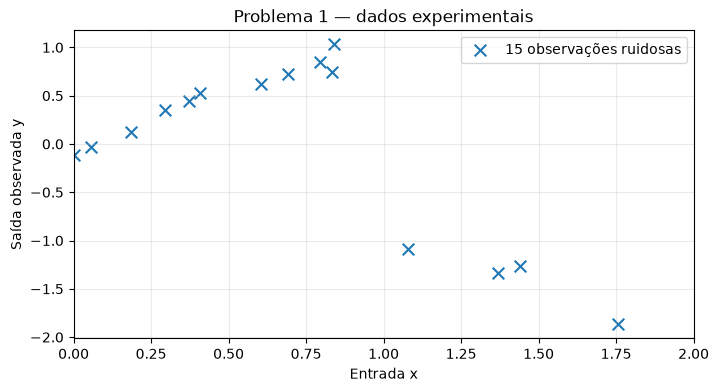

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(X_train, y_train, marker="x", s=70, label="15 observações ruidosas")
ax.set(xlabel="Entrada x", ylabel="Saída observada y", title="Problema 1 — dados experimentais")
ax.set_xlim(0.0, 2.0)
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()

### 5. Antes do próximo passo: uma decisão de modelagem

No próximo encontro, escolheremos **a função de média e o kernel** do primeiro GP. Ainda não faremos otimização de hiperparâmetros.

**Pergunta de pesquisa:** se o modelo não conhece a expressão de $f_{\mathrm{real}}$, o que significa assumir inicialmente que sua função de média é $m(x)=0$? Essa hipótese diz que a função verdadeira é zero, ou representa apenas a nossa expectativa anterior à observação dos dados?

Essa distinção será o ponto de partida para implementar o prior do GP.